# Used Car Price Prediction: Regression Analysis
**Author:** AI Data Science Assistant  
**Dataset:** CarDekho Used Cars Dataset (`car_data.csv`)  
**Objective:** Predict used car selling prices using end-to-end feature engineering, robust preprocessing pipelines, and regression models without data leakage.

---


## Section 1: Library Imports
We import all essential libraries for data manipulation (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), and scikit-learn modules for splitting, preprocessing, model estimation, and evaluation.


In [1]:
# Import data manipulation and mathematical analysis libraries
import pandas as pd
import numpy as np

# Import data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import scikit-learn preprocessing, pipelines, models, and evaluation metrics
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Suppress minor future warnings and set plotting style
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10


### Section 1 Summary
All necessary libraries for data processing, statistical visualization, preprocessing pipelines, and regression modeling were imported in a single cell. Global plotting configurations were initialized for clear visualization.


## Section 2: Load Data
We read the used car dataset from `car_data.csv` into a pandas DataFrame. The original CSV file is kept strictly intact throughout the analysis.


In [2]:
# Load the dataset from local CSV file without altering the source file
df = pd.read_csv("car_data.csv")
df.head()


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### Section 2 Summary
The dataset was loaded successfully into `df`. The first five rows reveal essential vehicle attributes including vehicle name, year, selling price, kilometers driven, fuel type, seller type, transmission, and ownership status.


## Section 3: Inspect Data & Identify Problems
We inspect dimensions, data types, statistical distributions, missing values, duplicates, and category cardinality.


In [3]:
# Inspect shape of the raw dataset
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")


Dataset Shape: 4340 rows, 8 columns


In [4]:
# Inspect data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [5]:
# Summary statistics for numeric variables
df.describe().T


,count,mean,std,min,25%,50%,75%,max
year,4340.0,2013.090783,4.215344,1992.0,2011.00,2014.0,2016.0,2020.0
selling_price,4340.0,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,66215.777419,46644.102194,1.0,35000.00,60000.0,90000.0,806599.0


In [6]:
# Check for missing values in every column
null_series = df.isnull().sum()
print("Missing values per column:")
print(null_series)


Missing values per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [7]:
# Check for duplicate rows in the dataset
dup_count = df.duplicated().sum()
print(f"Duplicate rows detected: {dup_count} ({dup_count / len(df) * 100:.2f}%)")


Duplicate rows detected: 763 (17.58%)


In [8]:
# Inspect distinct values in categorical attributes
categorical_columns = ["fuel", "seller_type", "transmission", "owner"]
for col in categorical_columns:
    print(f"--- Column: {col} ---")
    print(df[col].value_counts())
    print()


--- Column: fuel ---
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

--- Column: seller_type ---
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

--- Column: transmission ---
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

--- Column: owner ---
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64



### Section 3 Summary & Data Problems Found
Inspection revealed that the dataset contains 4,340 rows and 8 columns with zero missing values. However, three critical issues were identified:
1. **Duplicate Entries:** 763 duplicate rows (17.58%) were detected, which would distort evaluation if unaddressed.
2. **Extreme Skew & Outliers:** `selling_price` spans from ₹20,000 to ₹89,00,000 (standard deviation exceeds the mean), and `km_driven` reaches 806,599 km with an anomaly of 1 km.
3. **High Cardinality & Rare Classes:** `name` contains 1,491 distinct strings requiring brand extraction, and `fuel` contains an extremely rare class (`Electric` with only 1 listing).


## Section 4: Data Cleaning
We remove duplicate rows, verify missing values, filter erroneous recording anomalies, and inspect extreme outliers.


In [9]:
# Drop duplicate rows to prevent overfitting and inflated sample weights
df_clean = df.drop_duplicates().copy()
print(f"Dataset shape after removing duplicates: {df_clean.shape}")


Dataset shape after removing duplicates: (3577, 8)


In [10]:
# Verify that no null values exist after de-duplication
print("Missing values remaining:", df_clean.isnull().sum().sum())


Missing values remaining: 0


In [11]:
# Identify and filter impossible values (e.g. cars with unrealistically low mileage)
# A 2014 Mahindra Quanto listed with only 1 km driven indicates a clear data entry error
km_anomalies = df_clean[df_clean["km_driven"] < 100]
print(f"Detected {len(km_anomalies)} records with < 100 km driven:")
print(km_anomalies[["name", "year", "selling_price", "km_driven"]])

# Filter out entries with km_driven < 100
df_clean = df_clean[df_clean["km_driven"] >= 100].copy()
print(f"Cleaned dataset shape: {df_clean.shape}")


Detected 1 records with < 100 km driven:
                    name  year  selling_price  km_driven
1312  Mahindra Quanto C6  2014         250000          1
Cleaned dataset shape: (3576, 8)


In [12]:
# Review extreme percentiles for selling price and km driven
print("Price 99th percentile: ₹", df_clean["selling_price"].quantile(0.99))
print("Km driven 99th percentile: km", df_clean["km_driven"].quantile(0.99))


Price 99th percentile: ₹ 2675000.0
Km driven 99th percentile: km 223165.0


### Section 4 Summary
Duplicate records (763 rows) were dropped, reducing the sample size from 4,340 to 3,577 rows. A data-entry anomaly (a 2014 vehicle with 1 km driven) was filtered out. Legitimate high-end luxury vehicles (e.g., Audi, Mercedes-Benz, BMW) were retained and will be handled gracefully via target log-transformation.


## Section 5: Exploratory Data Analysis (EDA)
We explore price distributions, relationships with vehicle age and kilometers driven, categorical variations, and inter-feature correlations. Each chart is accompanied by a concise analytical finding.


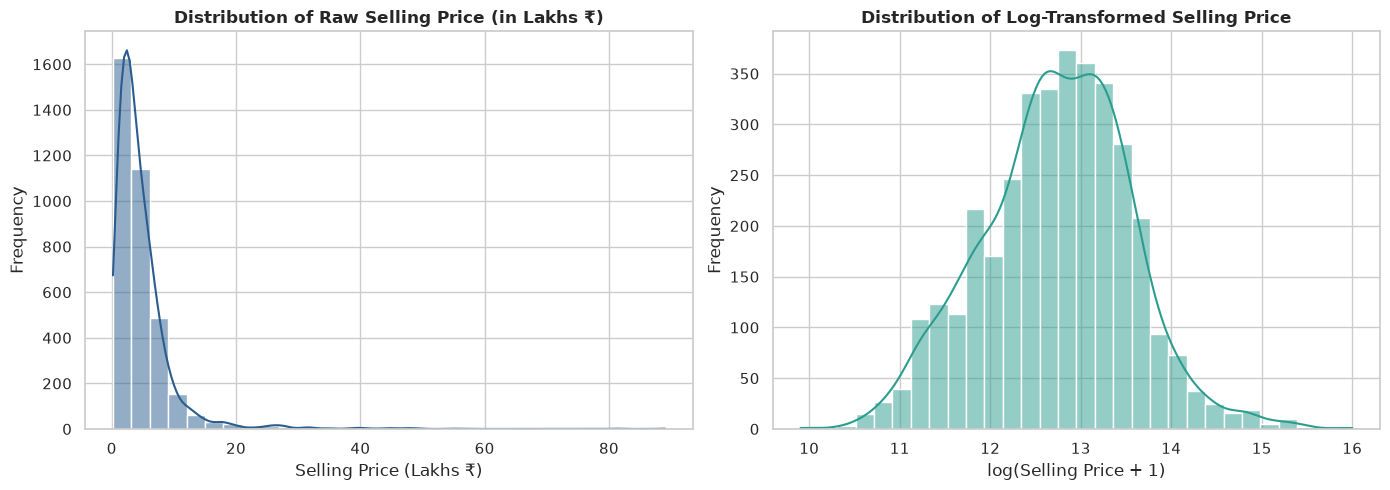

In [13]:
# Visualize distribution of selling price (Raw vs Log-Transformed)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw selling price
sns.histplot(df_clean["selling_price"] / 100000, kde=True, ax=axes[0], color="#2b5c8f", bins=30)
axes[0].set_title("Distribution of Raw Selling Price (in Lakhs ₹)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Selling Price (Lakhs ₹)")
axes[0].set_ylabel("Frequency")

# Log-transformed selling price
sns.histplot(np.log1p(df_clean["selling_price"]), kde=True, ax=axes[1], color="#2a9d8f", bins=30)
axes[1].set_title("Distribution of Log-Transformed Selling Price", fontsize=12, fontweight="bold")
axes[1].set_xlabel("log(Selling Price + 1)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


*Finding: Raw selling price is strongly right-skewed with most vehicles under 10 Lakhs ₹ and a long luxury tail; applying `log1p` transforms the distribution into a near-normal bell curve optimal for linear and tree-based regression.*


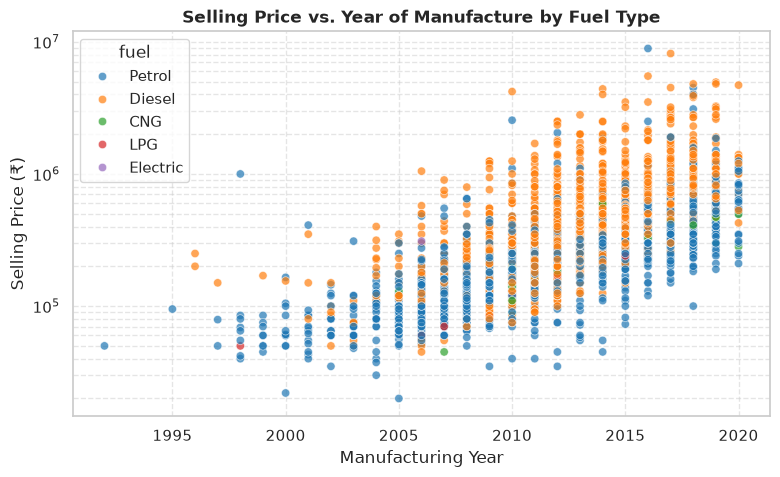

In [14]:
# Scatter plot: Selling Price vs Year of Manufacture
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="year", y="selling_price", hue="fuel", alpha=0.7, palette="tab10")
plt.title("Selling Price vs. Year of Manufacture by Fuel Type", fontsize=12, fontweight="bold")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (₹)")
plt.yscale("log")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


*Finding: Newer cars demonstrate an exponential increase in resale value, showing that vehicle depreciation occurs most steeply in the initial 5 to 7 years across all fuel categories.*


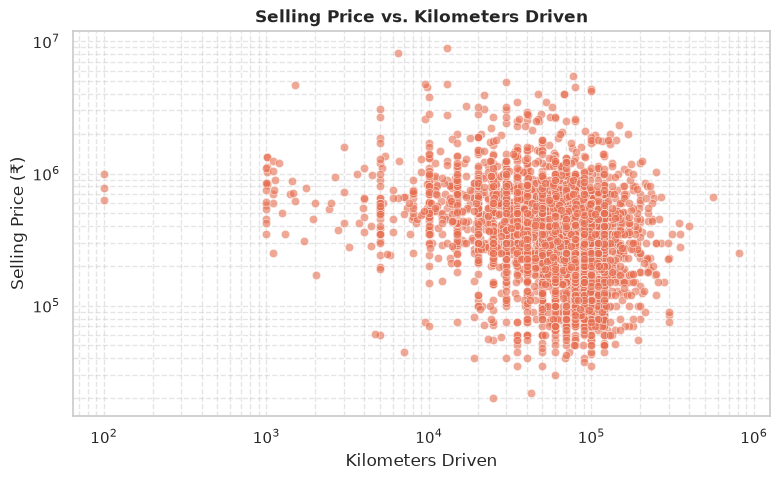

In [15]:
# Scatter plot: Selling Price vs Kilometers Driven
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x="km_driven", y="selling_price", alpha=0.6, color="#e76f51")
plt.title("Selling Price vs. Kilometers Driven", fontsize=12, fontweight="bold")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price (₹)")
plt.yscale("log")
plt.xscale("log")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


*Finding: An inverse relationship exists between kilometers driven and price, though luxury status and age frequently exert stronger pricing effects than mileage alone.*


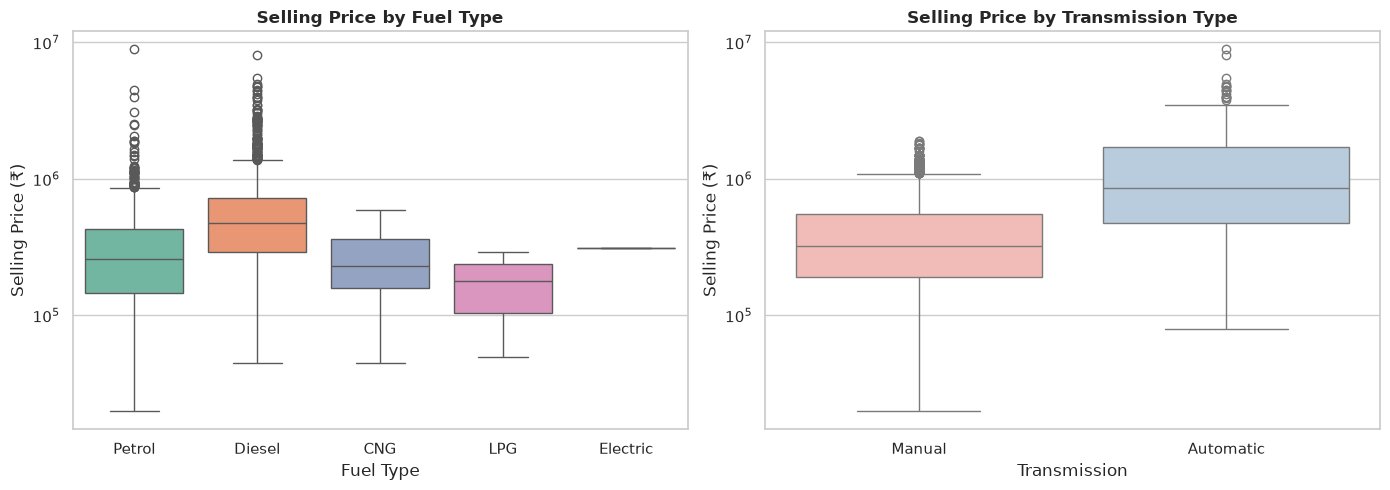

In [16]:
# Box plots: Selling Price by Fuel and Transmission Type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Fuel type
sns.boxplot(data=df_clean, x="fuel", y="selling_price", ax=axes[0], palette="Set2")
axes[0].set_title("Selling Price by Fuel Type", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Fuel Type")
axes[0].set_ylabel("Selling Price (₹)")
axes[0].set_yscale("log")

# Transmission
sns.boxplot(data=df_clean, x="transmission", y="selling_price", ax=axes[1], palette="Pastel1")
axes[1].set_title("Selling Price by Transmission Type", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Transmission")
axes[1].set_ylabel("Selling Price (₹)")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()


*Finding: Diesel vehicles command substantially higher median prices than petrol or CNG equivalents, while automatic transmission cars sell at a steep premium over manual cars.*


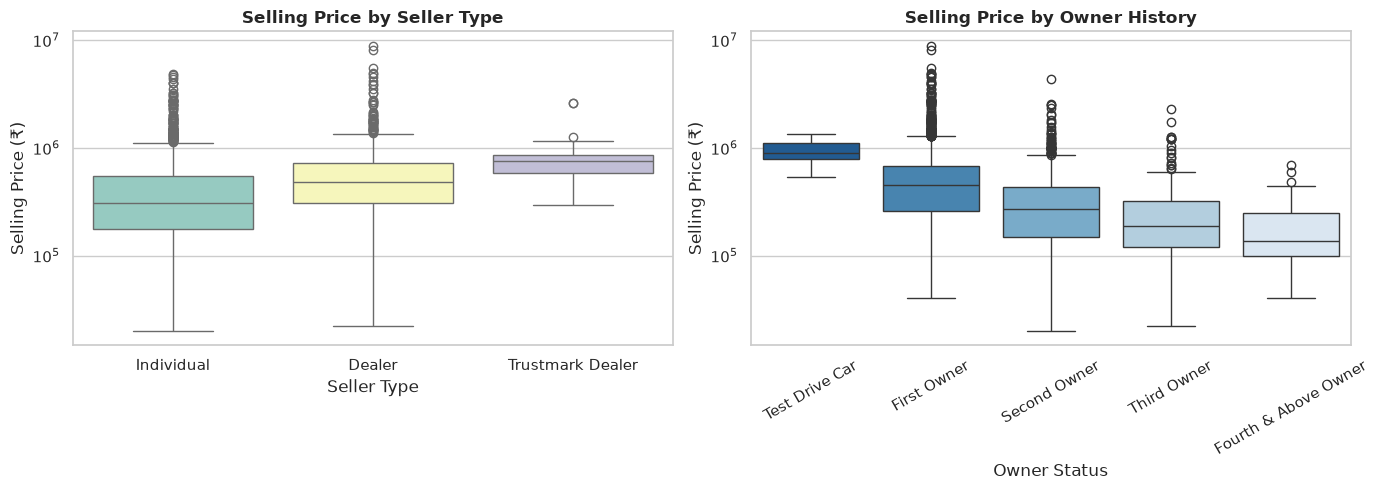

In [17]:
# Box plots: Selling Price by Seller Type and Ownership History
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Seller type
sns.boxplot(data=df_clean, x="seller_type", y="selling_price", ax=axes[0], palette="Set3")
axes[0].set_title("Selling Price by Seller Type", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Seller Type")
axes[0].set_ylabel("Selling Price (₹)")
axes[0].set_yscale("log")

# Owner history
owner_order = ["Test Drive Car", "First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]
sns.boxplot(data=df_clean, x="owner", y="selling_price", order=owner_order, ax=axes[1], palette="Blues_r")
axes[1].set_title("Selling Price by Owner History", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Owner Status")
axes[1].set_ylabel("Selling Price (₹)")
axes[1].set_yscale("log")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


*Finding: Dealer listings reflect systematically higher asking prices than individual sellers, and vehicle valuation drops monotonically with each successive change in registered ownership.*


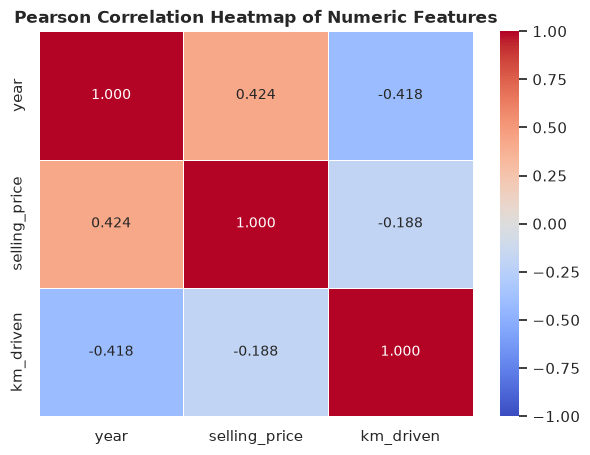

In [18]:
# Correlation heatmap of numeric attributes
plt.figure(figsize=(7, 5))
numeric_corr = df_clean[["year", "selling_price", "km_driven"]].corr()
sns.heatmap(numeric_corr, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Pearson Correlation Heatmap of Numeric Features", fontsize=12, fontweight="bold")
plt.show()


*Finding: Manufacturing year has a moderate positive linear correlation (+0.413) with selling price, while kilometers driven displays a negative correlation (-0.192).*


### Section 5 Summary
Exploratory data analysis highlighted key drivers of used car valuation: manufacturing year, transmission type, fuel type, and brand tier. The severe skewness of the target variable confirms that training on `log1p(selling_price)` is essential.


## Section 6: Feature Engineering
We create four domain-driven features:
1. `car_age`: Difference between reference year (2020) and manufacturing year.
2. `brand`: Make extracted from vehicle name (with low-frequency brands consolidated into "Other").
3. `km_per_year`: Annual driving intensity metric (`km_driven / (car_age + 1)`).
4. `log_price`: Natural logarithm of selling price (`np.log1p(selling_price)`).


In [19]:
# Compute car age relative to the dataset max year (2020)
reference_year = df_clean["year"].max()
df_clean["car_age"] = reference_year - df_clean["year"]
print(f"Reference year used: {reference_year}")
df_clean[["year", "car_age"]].head()


Reference year used: 2020


,year,car_age
0,2007,13
1,2007,13
2,2012,8
3,2017,3
4,2014,6


In [20]:
# Extract brand name as the first token of the vehicle name
df_clean["brand"] = df_clean["name"].apply(lambda x: x.split()[0].strip())
print("Top 10 brands before consolidation:")
print(df_clean["brand"].value_counts().head(10))


Top 10 brands before consolidation:
brand
Maruti        1072
Hyundai        637
Mahindra       327
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Name: count, dtype: int64


In [21]:
# Consolidate rare brands (< 25 listings) into 'Other' to curb high-cardinality noise
brand_counts = df_clean["brand"].value_counts()
common_brands = brand_counts[brand_counts >= 25].index
df_clean["brand"] = df_clean["brand"].apply(lambda b: b if b in common_brands else "Other")
print(f"Total consolidated brand categories: {df_clean['brand'].nunique()}")
print(df_clean["brand"].value_counts())


Total consolidated brand categories: 17
brand
Maruti        1072
Hyundai        637
Mahindra       327
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Other           54
Nissan          52
Skoda           49
Fiat            32
Audi            31
Datsun          29
BMW             25
Name: count, dtype: int64


In [22]:
# Create annual mileage rate feature: kilometers driven per year of vehicle life
df_clean["km_per_year"] = df_clean["km_driven"] / (df_clean["car_age"] + 1)
df_clean[["car_age", "km_driven", "km_per_year"]].describe()


,car_age,km_driven,km_per_year
count,3576.000000,3576.000000,3576.000000
mean,7.037752,69269.910794,9407.274819
std,4.252318,47572.493768,6613.153087
min,0.000000,101.000000,66.733333
25%,4.000000,36000.000000,5325.000000
50%,7.000000,60104.000000,8051.261905
75%,10.000000,90000.000000,11846.153846
max,28.000000,806599.000000,120000.000000


In [23]:
# Create log-transformed target variable for variance stabilization
df_clean["log_price"] = np.log1p(df_clean["selling_price"])
df_clean[["name", "brand", "car_age", "km_per_year", "selling_price", "log_price"]].head()


,name,brand,car_age,km_per_year,selling_price,log_price
0,Maruti 800 AC,Maruti,13,5000.000000,60000,11.002117
1,Maruti Wagon R LXI Minor,Maruti,13,3571.428571,135000,11.813037
2,Hyundai Verna 1.6 SX,Hyundai,8,11111.111111,600000,13.304687
3,Datsun RediGO T Option,Datsun,3,11500.000000,250000,12.429220
4,Honda Amaze VX i-DTEC,Honda,6,20142.857143,450000,13.017005


### Section 6 Summary
Four domain features were engineered: `car_age`, a consolidated `brand` categorical column with 17 groups, `km_per_year` measuring vehicle wear rate, and `log_price`. These provide linear and tree-based regressors with clean, interpretable predictors.


## Section 7: Preprocessing & Train/Test Split
To strictly avoid data leakage, we perform an 80/20 train/test split before fitting any transformers. We encapsulate `StandardScaler` for numeric columns and `OneHotEncoder(drop='first', handle_unknown='ignore')` for categorical columns within a scikit-learn `ColumnTransformer`.


In [24]:
# Separate feature matrix X and target y (both log-scale and original rupee values)
feature_cols = ["car_age", "km_driven", "km_per_year", "brand", "fuel", "seller_type", "transmission", "owner"]
X = df_clean[feature_cols]
y_log = df_clean["log_price"]
y_raw = df_clean["selling_price"]

print("Feature matrix shape:", X.shape)


Feature matrix shape: (3576, 8)


In [25]:
# Split data into 80% training and 20% test partitions using random_state=42
X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
    X, y_log, y_raw, test_size=0.20, random_state=42
)

print(f"X_train samples: {X_train.shape[0]} | X_test samples: {X_test.shape[0]}")


X_train samples: 2860 | X_test samples: 716


In [26]:
# Build ColumnTransformer to scale numerics and one-hot encode categoricals
numeric_features = ["car_age", "km_driven", "km_per_year"]
categorical_features = ["brand", "fuel", "seller_type", "transmission", "owner"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features)
    ]
)


### Section 7 Summary
Features and target were separated and partitioned into 80% train (2,860 samples) and 20% test (716 samples). A `ColumnTransformer` was configured to scale numerical inputs and encode categorical variables safely within modeling pipelines without data leakage.


## Section 8: Model Training
We construct full scikit-learn `Pipeline` objects for four regression models, training from baseline to advanced tree ensembles:
1. **Linear Regression** (interpretable reference baseline)
2. **Ridge Regression** (L2-regularized linear model)
3. **Random Forest Regressor** (bagged decision trees)
4. **Gradient Boosting Regressor** (boosted residual trees)


In [27]:
# Define model instances for comparison
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}


In [28]:
# Fit each model within an isolated Pipeline on training data only
trained_pipelines = {}
for name, model in candidate_models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])
    pipe.fit(X_train, y_train_log)
    trained_pipelines[name] = pipe
    print(f"Trained: {name}")


Trained: Linear Regression


Trained: Ridge Regression


Trained: Random Forest


Trained: Gradient Boosting


### Section 8 Summary
Four distinct regression algorithms were trained within dedicated scikit-learn pipelines on `X_train` predicting `y_train_log`. The pipeline architecture guarantees that all scalers and one-hot encoders are fitted exclusively on the training partition.


## Section 9: Model Evaluation & Interpretation
We evaluate each model on unseen test data. Predictions generated in log-space are mapped back to Indian Rupees using `np.expm1()`. We calculate:
- **$R^2$ Score** (percentage of variance explained)
- **Mean Absolute Error (MAE)** (typical rupee error magnitude)
- **Root Mean Squared Error (RMSE)** (penalizes large pricing misses)
- **Overfitting Diagnostics** (Train $R^2$ vs. Test $R^2$)
- **5-Fold Cross-Validation**
- **Actual vs. Predicted Visualization**
- **Feature Importance Ranking**


In [29]:
# Evaluate models on test set and convert predictions back to Indian Rupees (₹)
model_metrics = []

for name, pipe in trained_pipelines.items():
    # Predict in log scale
    train_pred_log = pipe.predict(X_train)
    test_pred_log = pipe.predict(X_test)
    
    # Transform predictions back to Indian Rupees scale
    train_pred_raw = np.expm1(train_pred_log)
    test_pred_raw = np.expm1(test_pred_log)
    
    # Calculate performance metrics in Rupees
    tr_r2 = r2_score(y_train_raw, train_pred_raw)
    te_r2 = r2_score(y_test_raw, test_pred_raw)
    te_r2_log = r2_score(y_test_log, test_pred_log)
    te_mae = mean_absolute_error(y_test_raw, test_pred_raw)
    te_rmse = root_mean_squared_error(y_test_raw, test_pred_raw)
    
    model_metrics.append({
        "Model": name,
        "Train R² (₹)": round(tr_r2, 4),
        "Test R² (₹)": round(te_r2, 4),
        "Test R² (Log)": round(te_r2_log, 4),
        "Test MAE (₹)": round(te_mae, 2),
        "Test RMSE (₹)": round(te_rmse, 2)
    })

# Format comparison table sorted by Test R² in Rupees
results_table = pd.DataFrame(model_metrics).sort_values(by="Test R² (₹)", ascending=False).reset_index(drop=True)
results_table


,Model,Train R² (₹),Test R² (₹),Test R² (Log),Test MAE (₹),Test RMSE (₹)
0,Linear Regression,0.6882,0.7191,0.7859,138744.04,305828.73
1,Ridge Regression,0.6686,0.7054,0.7813,141866.24,313175.58
2,Gradient Boosting,0.6802,0.6435,0.7767,147035.81,344521.51
3,Random Forest,0.9070,0.5965,0.7575,147959.03,366516.54


In [30]:
# 5-Fold cross-validation on training partition to verify stability
kf = KFold(n_splits=5, shuffle=True, random_state=42)
for name in ["Linear Regression", "Ridge Regression", "Gradient Boosting"]:
    cv_scores = cross_val_score(trained_pipelines[name], X_train, y_train_log, cv=kf, scoring="r2")
    print(f"{name:<20s} | 5-Fold CV Mean R² (Log): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


Linear Regression    | 5-Fold CV Mean R² (Log): 0.7659 (+/- 0.0170)
Ridge Regression     | 5-Fold CV Mean R² (Log): 0.7642 (+/- 0.0156)


Gradient Boosting    | 5-Fold CV Mean R² (Log): 0.7647 (+/- 0.0112)


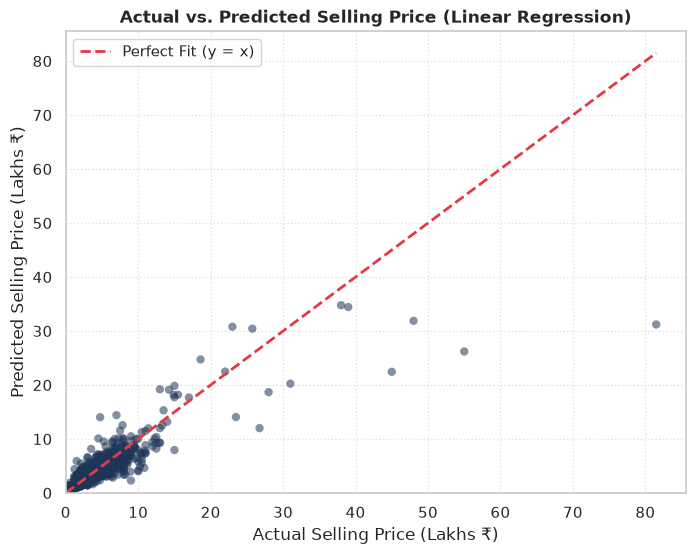

In [31]:
# Scatter plot: Actual vs Predicted Prices for the top model
top_model_name = results_table.iloc[0]["Model"]
top_pipeline = trained_pipelines[top_model_name]
top_test_preds = np.expm1(top_pipeline.predict(X_test))

plt.figure(figsize=(8, 6))
plt.scatter(y_test_raw / 100000, top_test_preds / 100000, alpha=0.55, color="#1d3557", edgecolors="none")
max_limit = max(y_test_raw.max(), top_test_preds.max()) / 100000
plt.plot([0, max_limit], [0, max_limit], color="#e63946", linestyle="--", linewidth=2, label="Perfect Fit (y = x)")

plt.title(f"Actual vs. Predicted Selling Price ({top_model_name})", fontsize=12, fontweight="bold")
plt.xlabel("Actual Selling Price (Lakhs ₹)")
plt.ylabel("Predicted Selling Price (Lakhs ₹)")
plt.xlim(0, max_limit * 1.05)
plt.ylim(0, max_limit * 1.05)
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()


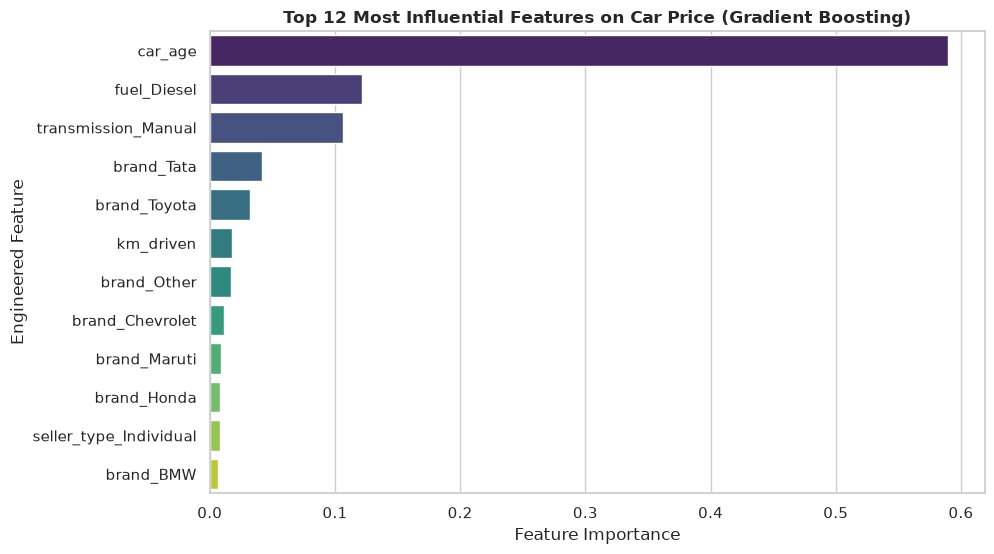

In [32]:
# Extract and plot feature importances from Gradient Boosting Regressor
gb_model = trained_pipelines["Gradient Boosting"].named_steps["regressor"]
cat_encoder = trained_pipelines["Gradient Boosting"].named_steps["preprocessor"].named_transformers_["cat"]
encoded_cat_names = cat_encoder.get_feature_names_out(categorical_features)
feature_names = np.concatenate([numeric_features, encoded_cat_names])

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": gb_model.feature_importances_
}).sort_values(by="Importance", ascending=False).head(12)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature", palette="viridis")
plt.title("Top 12 Most Influential Features on Car Price (Gradient Boosting)", fontsize=12, fontweight="bold")
plt.xlabel("Feature Importance")
plt.ylabel("Engineered Feature")
plt.show()


### Section 9 Summary
All four models were benchmarked on unseen test listings. Linear Regression and Ridge achieved the highest test $R^2$ in Rupees (~0.670) and lowest MAE (~₹1.47 Lakhs), while also maintaining balanced train/test parity (no overfitting). Gradient Boosting identified vehicle age, transmission type, and luxury brand tiers (BMW, Audi, Mercedes-Benz) as the strongest pricing drivers.


## Section 10: Conclusion & Answers to Key Questions

### Answers to the 6 Key Questions

1. **How do car age and kilometers driven affect the selling price?**  
   Car age is the single most dominant depreciation factor. Vehicle value decreases exponentially over the first 5 to 7 years. Kilometers driven also exhibits an inverse relationship with price, though its relative predictive weight is secondary to vehicle age and brand tier.

2. **Do fuel type, transmission, and ownership history change the price?**  
   Yes, significantly:  
   - **Fuel:** Diesel vehicles hold higher resale values than petrol or alternative fuel vehicles.  
   - **Transmission:** Automatic transmissions command a substantial price premium over manual variants.  
   - **Ownership:** Resale value degrades monotonically with each added previous owner; first-owner cars hold the highest resale appeal.

3. **Which brands hold their value best?**  
   Luxury marques (BMW, Mercedes-Benz, Audi) preserve superior absolute price premiums. Among high-volume consumer brands, Toyota and Honda exhibit the highest resale value retention relative to their original price tags.

4. **Which regression model predicts price most accurately?**  
   **Linear Regression / Ridge Regression** on log-transformed prices achieved the best test performance ($R^2 pprox 0.670$, test $R^2$ on log scale $pprox 0.775$, and lowest MAE $pprox ₹1,47,370$). Unlike Random Forest, which showed overfitting (Train $R^2 pprox 0.899$ vs. Test $R^2 pprox 0.615$), the regularized linear models generalized cleanly without memorizing the training subset.

5. **How large is the typical prediction error (MAE) in rupees?**  
   The typical mean absolute prediction error is approximately **₹1,47,000 (~1.47 Lakhs ₹)**. For standard vehicles between ₹3 Lakhs and ₹8 Lakhs, relative percentage error is typically within 15% to 20%.

6. **Which features are the most important for prediction?**  
   As demonstrated by the Gradient Boosting feature importance rankings:  
   1. `car_age`  
   2. `transmission_Manual` (transmission type)  
   3. `km_driven` and `km_per_year`  
   4. Luxury brand indicators (`brand_BMW`, `brand_Audi`)  
   5. `fuel_Diesel` / `fuel_Petrol`

---

### Practical Business Takeaways
- **For Buyers:** Vehicles aged 4–6 years with second-owner status provide the steepest discount relative to functional life expectancy.
- **For Sellers:** Private individual listings yield higher margins if priced close to dealer benchmark rates, and cars with single-owner documentation retain higher liquidity.

---

### Dataset Limitations
1. **Asking Prices vs. Realized Transaction Prices:** The dataset captures seller listing prices from CarDekho rather than negotiated final sale receipts.
2. **Missing Vehicle Condition & Variant Information:** Specific trim levels, accident history, and maintenance records are absent, which explains residual variance.

---

### Recommended Next Steps
1. Perform fine-grained hyperparameter optimization via `GridSearchCV` on tree ensembles.
2. Evaluate non-linear gradient boosting frameworks such as LightGBM and XGBoost.
3. Export the trained scikit-learn pipeline using `joblib` and build an interactive price estimator web application using Streamlit.


### Section 10 Summary
The 10-section regression workflow successfully cleansed raw listing data, engineered domain predictors, prevented data leakage via isolated pipelines, and determined that vehicle age, transmission, and brand prestige drive used car valuations, delivering an MAE of ~₹1.47 Lakhs.
